# Q-Learning Agent for Taxi-v4
Topics in AI, Assignment 1. Tabular Q-learning implemented from scratch with Gymnasium.

In [1]:
import numpy as np
import csv
from IPython.display import Image, display
from agent import QLearningAgent
from utils import (make_env, train, evaluate, random_baseline,
                   plot_curves, make_gif, moving_avg, ENV_ID)
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
env = make_env()
print("Environment:", ENV_ID)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Max steps per episode:", env.spec.max_episode_steps)
s, _ = env.reset(seed=0)
print("Example start state:", s)
print("Illegal pickup reward:", env.step(4)[1])
print("Move reward:", env.step(0)[1])

Environment: Taxi-v4
Observation space: Discrete(500)
Action space: Discrete(6)
Max steps per episode: 200
Example start state: 314
Illegal pickup reward: -10
Move reward: -1


In [3]:
rb_mean, rb_std = random_baseline(env, 100)
print(f"Random policy: mean reward = {rb_mean:.2f}, std = {rb_std:.2f}")

Random policy: mean reward = -774.00, std = 74.14


In [4]:
EPISODES, CHUNK = 10000, 1000
agent = QLearningAgent(500, 6, alpha=0.1, gamma=0.99,
                       eps_start=1.0, eps_end=0.05, eps_decay=0.999, seed=0)
all_rewards = []
for i in range(0, EPISODES, CHUNK):
    r = train(env, agent, CHUNK, seed=0 if i == 0 else None)
    all_rewards.extend(r)
    print(f"Episodes {i+1:>5}-{i+CHUNK:>5} | avg reward {np.mean(r):8.2f} | epsilon {agent.epsilon:.3f}")
all_rewards = np.array(all_rewards)

Episodes     1- 1000 | avg reward  -354.75 | epsilon 0.368
Episodes  1001- 2000 | avg reward   -15.26 | epsilon 0.135
Episodes  2001- 3000 | avg reward     3.17 | epsilon 0.050
Episodes  3001- 4000 | avg reward     5.33 | epsilon 0.050
Episodes  4001- 5000 | avg reward     5.27 | epsilon 0.050
Episodes  5001- 6000 | avg reward     5.29 | epsilon 0.050
Episodes  6001- 7000 | avg reward     4.98 | epsilon 0.050
Episodes  7001- 8000 | avg reward     5.20 | epsilon 0.050
Episodes  8001- 9000 | avg reward     5.05 | epsilon 0.050
Episodes  9001-10000 | avg reward     5.42 | epsilon 0.050


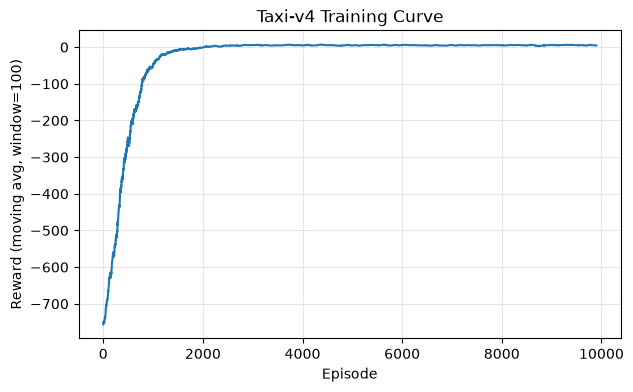

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(moving_avg(all_rewards, 100))
plt.xlabel("Episode"); plt.ylabel("Reward (moving avg, window=100)")
plt.title(f"{ENV_ID} Training Curve"); plt.grid(alpha=0.3)
plt.show()

In [6]:
mean, std, steps = evaluate(env, agent, 100)
print(f"Greedy policy: mean reward = {mean:.2f}, std = {std:.2f}, mean steps = {steps:.2f}")
print(f"Random policy: mean reward = {rb_mean:.2f}")

Greedy policy: mean reward = 7.53, std = 2.43, mean steps = 13.47
Random policy: mean reward = -774.00


In [7]:
with open("results/sweep_results.csv") as f:
    for row in csv.reader(f):
        print(" | ".join(f"{x:>18}" for x in row))

         parameter |              value |  train_last100_avg | greedy_eval_reward |  greedy_eval_steps
             alpha |               0.01 |             -48.34 |            -174.55 |             177.07
             alpha |                0.1 |               5.44 |               7.64 |              13.36
             alpha |                0.5 |               5.17 |               7.92 |              13.08
             alpha |                0.9 |                5.4 |               8.04 |              12.96
             gamma |                0.5 |               4.08 |             -60.11 |              74.18
             gamma |                0.9 |               5.72 |               8.08 |              12.92
             gamma |               0.99 |               5.44 |               7.64 |              13.36
         eps_decay |               0.99 |               5.67 |               7.73 |              13.27
         eps_decay |              0.999 |               5.44 |           

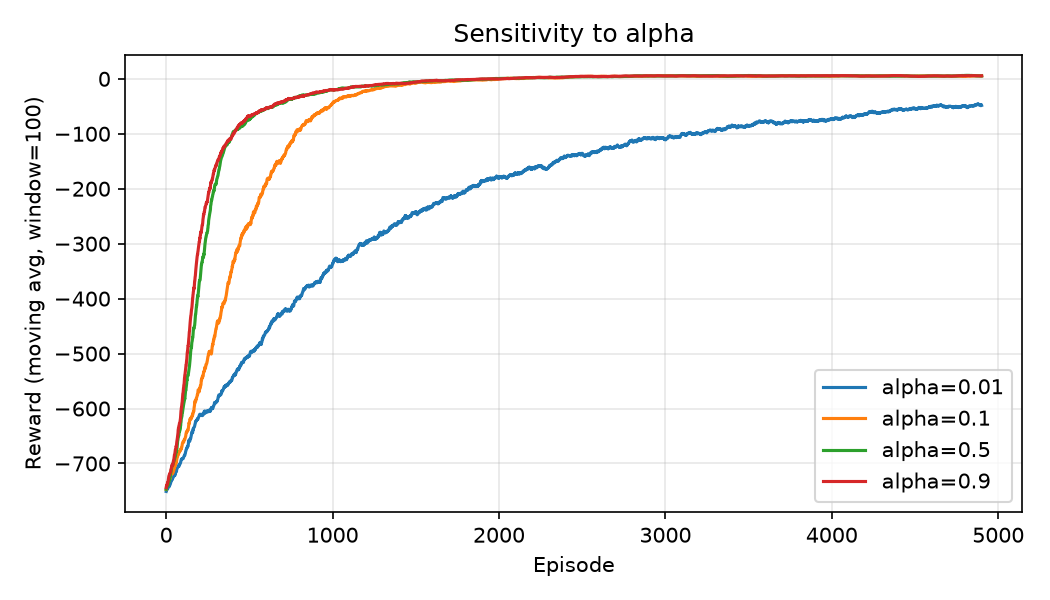

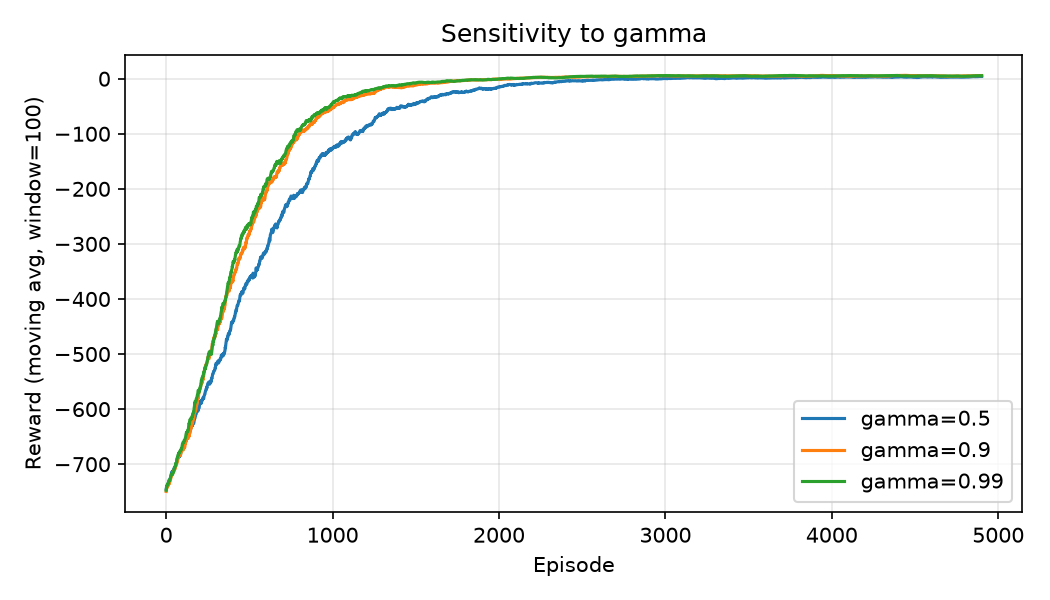

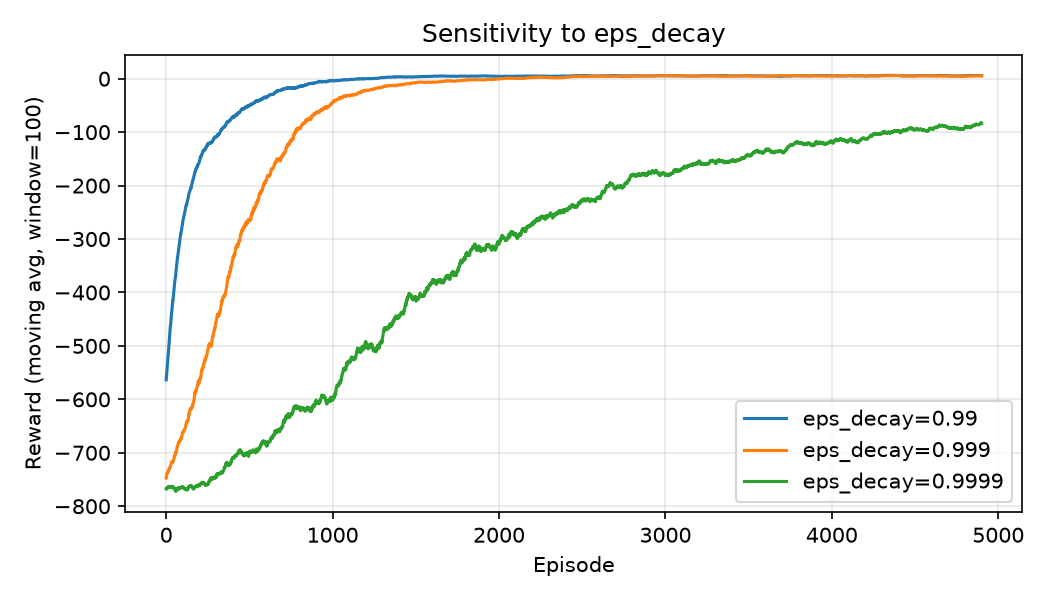

In [8]:
for p in ["alpha", "gamma", "eps_decay"]:
    display(Image(filename=f"results/sensitivity_{p}.png"))

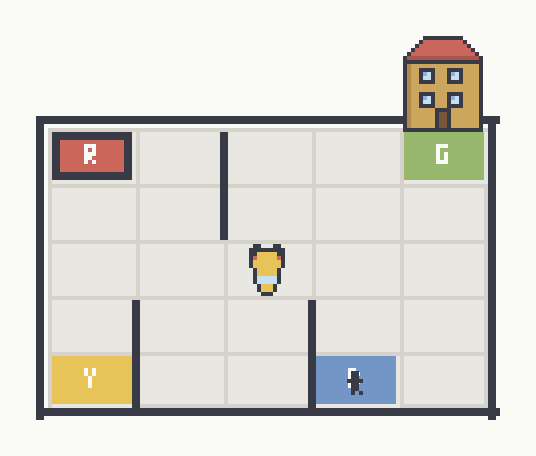

In [9]:
display(Image(filename="taxi_agent.gif"))